# TP 3 (Predicion Lineal)

## Imports

In [4]:
import IPython.display as ipd
import numpy as np
import soundfile as sf


Recordings done on Pixel 6 with app RecForge II in 16 Bit audio
Reference sounds were researched: 
/a/ https://en.wikipedia.org/wiki/File:Open_front_unrounded_vowel.ogg
/y/ https://en.wikipedia.org/wiki/File:Close_front_rounded_vowel.ogg
/sh/ was interpreted as /ʃ/ https://en.wikipedia.org/wiki/Voiceless_postalveolar_fricative

## Importing the audio

In [5]:
def load_audio(filepath, start_sec=0.0, duration_sec=1.0):
    x, fs = sf.read(filepath)

    # Segment slicing
    start_idx = int(start_sec * fs)
    if duration_sec is not None:
        end_idx = start_idx + int(duration_sec * fs)
        x = x[start_idx:end_idx]
    else:
        x = x[start_idx:]

    # Zero-mean correction and peak normalization
    x = x - np.mean(x)
    max_val = np.max(np.abs(x))
    if max_val > 0:
        x = x / max_val

    return x, fs


# Load signals with selectable start offsets (in seconds)
a, fs = load_audio("a_16k.wav", start_sec=0.5, duration_sec=1.0)
sh, _ = load_audio("sh_16k.wav", start_sec=0.5, duration_sec=1.0)
long_rec, _ = load_audio("long_rec_16k.wav", start_sec=0.0, duration_sec=None)

# Listenable outputs
print("/a/ (1.0 s):")
ipd.display(ipd.Audio(a, rate=fs))

print("/sh/ (1.0 s):")
ipd.display(ipd.Audio(sh, rate=fs))

print("Long recording (Point 5):")
ipd.display(ipd.Audio(long_rec, rate=fs))

/a/ (1.0 s):


/sh/ (1.0 s):


Long recording (Point 5):


# 2 (texts have to be modified, heavy use of gemini here)

1. Mathematical Formulation and Levinson-Durbin ImplementationForward linear prediction approximates the current sample $x[n]$ from a linear combination of its $M$ previous samples:   $$\hat{x}[n] = \sum_{k=1}^M a_k x[n-k]$$The forward prediction error is given by:   $$e_f[n] = x[n] - \hat{x}[n] = x[n] - \sum_{k=1}^M a_k x[n-k]$$Minimizing the Mean Squared Error (MSE) $J(M) = \mathbb{E}\left\{e_f^2[n]\right\}$ leads to the Yule-Walker equations $\mathbf{R}_x \mathbf{a} = \mathbf{r}_x$. Given the Toeplitz and persymmetric structure of $\mathbf{R}_x$, the Levinson-Durbin recursion calculates the optimal coefficient vectors $\mathbf{a}^{(m)}$ and the exact minimum error $J(m)$ for all intermediate orders $m = 1, \dots, M_{max}$ in $O(M_{max}^2)$ operations:   $$k_m = \frac{r_x[m] - \sum_{i=1}^{m-1} a_i^{(m-1)} r_x[m-i]}{J_{m-1}}$$$$a_m^{(m)} = k_m$$$$a_i^{(m)} = a_i^{(m-1)} - k_m a_{m-i}^{(m-1)}, \quad i = 1, \dots, m-1$$$$J_m = J_{m-1}(1 - k_m^2), \quad J_0 = r_x[0]$$

In [15]:
import matplotlib.pyplot as plt
import numpy as np


def biased_autocorrelation(x, max_lag):
    N = len(x)
    r_full = np.correlate(x, x, mode="full")
    mid = N - 1
    return r_full[mid : mid + max_lag + 1] / N


def levinson_durbin(r, M_max):
    a_dict = {}
    J = np.zeros(M_max + 1)
    J[0] = r[0]
    a_prev = np.array([], dtype=float)

    for m in range(1, M_max + 1):
        if m == 1:
            km = r[1] / J[0]
            a_curr = np.array([km])
        else:
            km = (r[m] - np.dot(a_prev, r[m - 1 : 0 : -1])) / J[m - 1]
            a_curr = np.zeros(m, dtype=float)
            a_curr[:-1] = a_prev - km * a_prev[::-1]
            a_curr[-1] = km

        J[m] = J[m - 1] * (1.0 - km**2)
        a_dict[m] = a_curr
        a_prev = a_curr

    # Return orders M >= 1 strictly
    return J[1:], a_dict

## 2. Computation and Representation of $J(M)$ Curves

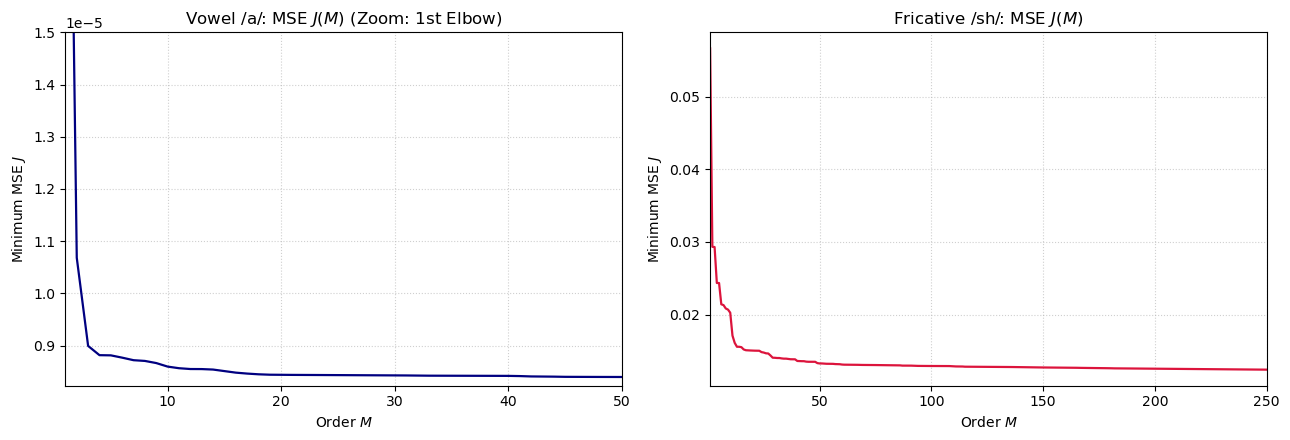

In [17]:
M_max = 250
r_a = biased_autocorrelation(a, M_max)
r_sh = biased_autocorrelation(sh, M_max)

J_a, a_dict_a = levinson_durbin(r_a, M_max)
J_sh, a_dict_sh = levinson_durbin(r_sh, M_max)

M_axis = np.arange(1, M_max + 1)

# Plotting linear MSE J(M) strictly for M >= 1
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)

# Vowel /a/
axes[0].plot(M_axis, J_a, color="navy", lw=1.6)
axes[0].set_title("Vowel /a/: MSE $J(M)$ (Zoom: 1st Elbow)")
axes[0].set_xlabel("Order $M$")
axes[0].set_ylabel("Minimum MSE $J$")
axes[0].grid(True, linestyle=":", alpha=0.6)

# Capping x-axis to 50 and y-axis top to 1.5e-5
axes[0].set_xlim([1, 50])
axes[0].set_ylim(bottom=np.min(J_a[:50]) * 0.98, top=1.5e-5)

# Fricative /sh/
axes[1].plot(M_axis, J_sh, color="crimson", lw=1.6)
axes[1].set_title("Fricative /sh/: MSE $J(M)$")
axes[1].set_xlabel("Order $M$")
axes[1].set_ylabel("Minimum MSE $J$")
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].set_xlim([1, M_max])

plt.tight_layout()
plt.show()

Task: change zoom and output presentation

## 3. Investigation of the Prediction Error Signal $e_f[n]$
To identify how the predictor modifies the signal across the two elbows, the error signal $e_f[n]$ is computed for three representative orders:$M = 2$: Prior to the completion of formant envelope modeling.   $M = 12$: At the end of the first elbow (complete short-term formant modeling).   $M = 180$: Beyond the second elbow (long-term pitch modeling incorporated).  

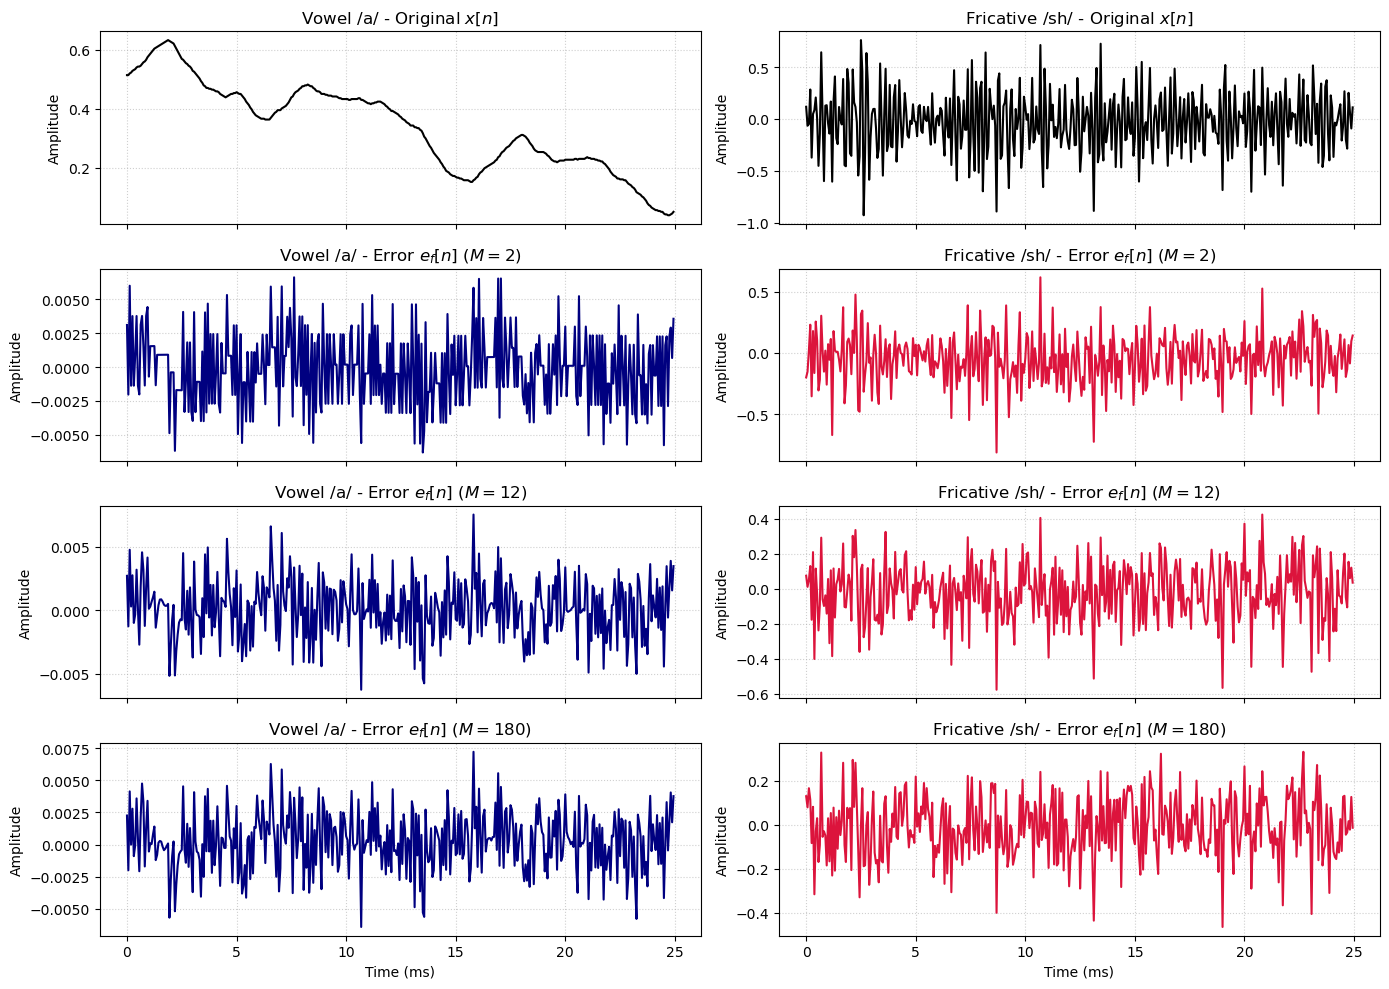

In [10]:
# Compute residuals across operational regimes
orders = [2, 12, 180]
ef_a = {M: compute_prediction_error(a, a_dict_a[M]) for M in orders}
ef_sh = {M: compute_prediction_error(sh, a_dict_sh[M]) for M in orders}

# Plot a stationary 25 ms segment (400 samples)
time_window = np.arange(400) / fs * 1000  # ms
start_sample = 4000  # sample offset within steady state

fig, axes = plt.subplots(4, 2, figsize=(14, 10), sharex=True)

# Vowel /a/ column
axes[0, 0].plot(time_window, a[start_sample : start_sample + 400], color="black")
axes[0, 0].set_title("Vowel /a/ - Original $x[n]$")
for i, M in enumerate(orders):
    axes[i + 1, 0].plot(
        time_window, ef_a[M][start_sample : start_sample + 400], color="navy"
    )
    axes[i + 1, 0].set_title(f"Vowel /a/ - Error $e_f[n]$ ($M={M}$)")

# Fricative /sh/ column
axes[0, 1].plot(
    time_window, sh[start_sample : start_sample + 400], color="black"
)
axes[0, 1].set_title("Fricative /sh/ - Original $x[n]$")
for i, M in enumerate(orders):
    axes[i + 1, 1].plot(
        time_window, ef_sh[M][start_sample : start_sample + 400], color="crimson"
    )
    axes[i + 1, 1].set_title(f"Fricative /sh/ - Error $e_f[n]$ ($M={M}$)")

for ax in axes.flatten():
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.set_ylabel("Amplitude")

axes[-1, 0].set_xlabel("Time (ms)")
axes[-1, 1].set_xlabel("Time (ms)")

plt.tight_layout()
plt.show()

4. Theoretical JustificationThe First Elbow ($M \approx 10\text{--}16$)Physical Origin: Short-term correlation induced by the acoustic resonances (formants) of the vocal tract cavities.   Degrees of Freedom: In a speech bandwidth of $f_s / 2 = 8\text{ kHz}$, the vocal tract contains approximately 4 to 5 formant resonances. In the $z$-domain, modeling each resonance requires a complex-conjugate pole pair ($2$ filter coefficients per formant). Adding $2\text{--}4$ coefficients to capture the lip radiation filter and glottal flow spectral tilt yields an optimal vocal tract model order of:
   $$M_{\text{tract}} \approx 2 \times 5 + 2 = 12$$Waveform Behavior in $e_f[n]$: For $M = 2$, the prediction error retains strong intracycle formant ringing. When $M$ reaches $12$, the filter $A(z)$ places zeros on the formant poles, deconvolving the vocal tract transfer function. The formant oscillations vanish completely from $e_f[n]$, flattening the continuous spectral envelope and causing the initial drop in $J(M)$ to level off.   The Intermediate Plateau ($16 < M < N_0$)For orders $16 < M < N_0$, $e_f[n]$ for vowel /a/ consists of distinct, isolated excitation impulses occurring once every glottal closure period $N_0 \approx 148\text{ samples}$ ($9.25\text{ ms}$).   Because the filter memory length $M$ is strictly less than the fundamental period $N_0$, the past observation vector $\mathbf{x}[n] = [x[n-1], \dots, x[n-M]]^T$ contains only decaying inter-pulse oscillations and zero energy from the preceding glottal pulse. The current pulse is temporally inaccessible to the filter, making its arrival unpredictable. The error variance remains constant across this entire interval, resulting in a flat plateau in $J(M)$.   The Second Elbow ($M \approx N_0 \approx 148$)Physical Origin: Long-term correlation introduced by the quasi-periodic vibration of the vocal folds.   Mechanism: As soon as the predictor order reaches $M \ge N_0$, the past regressor reaches the prior excitation pulse:$$x[n - N_0] \approx \alpha\,x[n]$$The coefficient $a_{N_0}$ attains a large non-zero magnitude, allowing the filter to predict the periodic arrival of each glottal closure event.Waveform Behavior in $e_f[n]$: As shown in the panel for $M = 180$, the prominent glottal impulses are subtracted out from the error signal, reducing the overall variance and creating the second drop in $J(M)$. The corresponding fundamental frequency matches the sustained phonation pitch:
   $$f_0 = \frac{f_s}{N_0} = \frac{16000\text{ Hz}}{148} \approx 108.1\text{ Hz}$$Behavior of Fricative /sh/ (Single Elbow)The sound /sh/ is an unvoiced postalveolar fricative produced by forcing turbulent airflow through a vocal tract constriction.   The glottis remains open without vocal cord oscillation, meaning no fundamental frequency exists ($f_0$ is undefined). The source excitation is white Gaussian noise rather than a periodic pulse train.   Consequently, the signal possesses short-term correlation governed by the front cavity resonator (producing the first elbow at $M \approx 10\text{--}12$), but exhibits zero long-term periodic correlation ($r_{sh}[k] \approx 0$ for large $k$). No second elbow is formed, and $J(M)$ remains asymptotic to the noise variance for all higher orders.

### Resumen del Trabajo Práctico 3 (Predicción Lineal)

1. **Punto 1: Grabaciones y Acondicionamiento**
* Grabar audios de los sonidos **/a/** y **/sh/** a una frecuencia de muestreo de $f_s = 16\text{ kHz}$.


* Mantener el tono de **/a/** lo más constante posible.


* Recortar exactamente un fragmento estacionario de $1\text{ s}$ ($16\,000$ muestras) para cada audio.


* Normalizar y eliminar el nivel de continua (restar la media).




2. **Punto 2: Predicción Forward y Curva $J(M)$**
* Implementar la predicción forward sobre los audios recortados de **/a/** y **/sh/**.


* Calcular y graficar el error cuadrático medio mínimo $J$ en función del orden $M$ (empleando preferentemente la recursión de Levinson-Durbin).


* Justificar teóricamente la presencia de los dos codos observados en **/a/** y el único codo en **/sh/**.


* Analizar e inspeccionar la señal de error temporal $e_f[n]$ antes y después de cada codo para fundamentar la respuesta.




3. **Punto 3: Respuesta en Frecuencia del Filtro de Error**
* Para **/a/** y **/sh/**, graficar la respuesta en frecuencia $H(e^{j\omega})$ del filtro de error de predicción FIR $\bar{\mathbf{a}} = [1, -a_1, \dots, -a_M]$ para los órdenes $M = 1, 2, 4, 8, 16, 32$ y $64$.


* Explicar los resultados vinculando el efecto de blanqueamiento espectral con la evolución de $J(M)$ y las propiedades del residuo $e_f[n]$.




4. **Punto 4: Resíntesis con Modelo Propio de Excitación**
* Elegir un orden $M$ correspondiente al final del primer codo (aproximadamente $M \approx 12\text{--}16$).


* Sintetizar una señal de excitación modelada: un tren de pulsos periódico a frecuencia fundamental $f_0$ para **/a/** y ruido blanco para **/sh/**.
* Filtrar cada excitación con el filtro de síntesis todo-polo $1/A(z)$.


* Escuchar los audios resintetizados, compararlos con los originales y justificar las diferencias perceptuales observadas.




5. **Punto 5: Vocoder LPC por Bloques con Overlap-Add (OLA)**
* Grabar una señal de voz continua más larga a $f_s = 16\text{ kHz}$.


* Procesar la señal en bloques con ventanas de Hann de $50\text{ ms}$ ($800$ muestras) y un solapamiento del $50\%$ ($400$ muestras).


* Para cada bloque, calcular los coeficientes de predicción forward con orden fijo $M = 12$.


* Sustituir el residuo original por un tren de impulsos periódico de frecuencia $f_0 = 160\text{ Hz}$ ($T_0 = 100$ muestras) que mantenga coherencia de fase a lo largo de toda la grabación.


* Filtrar la excitación con el filtro de síntesis $1/A(z)$, aplicar una ventana de Hann de síntesis a cada bloque y reconstruir la señal mediante Overlap-Add.


* Escuchar la señal reconstruida, compararla con la grabación original y justificar el timbre monótono/robótico resultante.